[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/matrix-operations-and-lu-decomposition/notebook.ipynb)

# Matrix Operations and LU Decomposition: hands-on

This notebook goes with the [topic README](README.md). You will test the rules of matrix algebra, see why order matters, build an inverse and an LU factorization from scratch, watch a determinant scale areas, and see why factoring once pays off. It needs NumPy and Matplotlib, plus `scipy.linalg` for the LU comparison, and runs in a few seconds on a CPU.

Run the cells from top to bottom. After each demo, change a number and run it again.

In [1]:
%matplotlib inline
import time

import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=3, suppress=True)


def best_time(func, repeats=3):
    """Run func a few times and return the fastest time in seconds."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        func()
        times.append(time.perf_counter() - start)
    return min(times)

## 1. Rules for matrix operations

### Order matters: shear and quarter turn

A matrix is a machine that moves points. We use a letter F made of 10 corner points (the columns of a $2 \times 10$ matrix) and two machines: a **shear** that slides the shape sideways in proportion to its height, and a **quarter turn** that rotates it by 90 degrees counterclockwise. The product `R @ S` means "shear first, then turn", because the matrix nearest the points acts first.

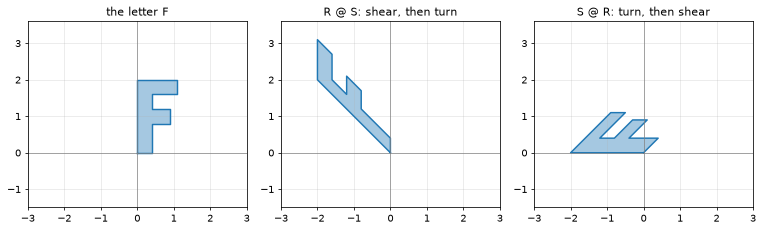

R @ S =
 [[ 0 -1]
 [ 1  1]]
S @ R =
 [[ 1 -1]
 [ 1  0]]


In [2]:
F = np.array([[0, 0.4, 0.4, 0.9, 0.9, 0.4, 0.4, 1.1, 1.1, 0],
              [0, 0,   0.8, 0.8, 1.2, 1.2, 1.6, 1.6, 2.0, 2.0]])

S = np.array([[1, 1],
              [0, 1]])        # shear: x moves by an amount equal to y
R = np.array([[0, -1],
              [1,  0]])       # quarter turn, counterclockwise


def draw(ax, points, title):
    closed = np.column_stack([points, points[:, 0]])
    ax.fill(closed[0], closed[1], alpha=0.4)
    ax.plot(closed[0], closed[1], lw=1.5)
    ax.set_aspect("equal")
    ax.axhline(0, color="gray", lw=0.7)
    ax.axvline(0, color="gray", lw=0.7)
    ax.set_xlim(-3, 3)
    ax.set_ylim(-1.5, 3.6)
    ax.grid(alpha=0.3)
    ax.set_title(title)


fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
draw(axes[0], F, "the letter F")
draw(axes[1], (R @ S) @ F, "R @ S: shear, then turn")
draw(axes[2], (S @ R) @ F, "S @ R: turn, then shear")
plt.tight_layout()
plt.show()

print("R @ S =\n", R @ S)
print("S @ R =\n", S @ R)

The two results are different shapes, so $RS \neq SR$. Now the laws that **do** hold. We check them on random matrices (a seed keeps them the same on every run). `np.allclose` compares numbers up to rounding error.

In [3]:
rng = np.random.default_rng(0)
A, B, C_ = (rng.normal(size=(4, 4)) for _ in range(3))

print("(AB)C = A(BC)        :", np.allclose((A @ B) @ C_, A @ (B @ C_)))
print("A(B + C) = AB + AC   :", np.allclose(A @ (B + C_), A @ B + A @ C_))
print("(A + B)C = AC + BC   :", np.allclose((A + B) @ C_, A @ C_ + B @ C_))
print("A I = A              :", np.allclose(A @ np.eye(4), A))
print("A^3 = A A A          :", np.allclose(np.linalg.matrix_power(A, 3), A @ A @ A))
print("AB = BA              :", np.allclose(A @ B, B @ A))

# AB can be zero even though neither A nor B is zero
P = np.array([[1, 0], [0, 0]])
Q = np.array([[0, 0], [0, 1]])
print("\nP =", P.tolist(), " Q =", Q.tolist(), " P @ Q =", (P @ Q).tolist())

(AB)C = A(BC)        : True
A(B + C) = AB + AC   : True
(A + B)C = AC + BC   : True
A I = A              : True
A^3 = A A A          : True
AB = BA              : False

P = [[1, 0], [0, 0]]  Q = [[0, 0], [0, 1]]  P @ Q = [[0, 0], [0, 0]]


### Associativity saves work

Because $(AB)\mathbf{x} = A(B\mathbf{x})$, we may choose the cheaper order. For $n \times n$ matrices, $AB$ costs about $n^3$ multiplications, but a matrix times a vector costs only about $n^2$. So $A(B\mathbf{x})$ needs two cheap products and $(AB)\mathbf{x}$ one expensive one.

In [4]:
n = 1500
rng = np.random.default_rng(1)
A = rng.normal(size=(n, n))
B = rng.normal(size=(n, n))
x = rng.normal(size=n)

same = np.allclose((A @ B) @ x, A @ (B @ x))
t_slow = best_time(lambda: (A @ B) @ x)
t_fast = best_time(lambda: A @ (B @ x))

print("same answer:", same)
print(f"multiplications: (AB)x about {n**3:.1e}, A(Bx) about {2 * n**2:.1e}")
print(f"(AB)x is about {t_slow / t_fast:.0f} times slower than A(Bx) on this machine (the exact number varies)")

same answer: True
multiplications: (AB)x about 3.4e+09, A(Bx) about 4.5e+06
(AB)x is about 64 times slower than A(Bx) on this machine (the exact number varies)


### Four ways to see one product

With $`A = \begin{bmatrix}1&2\\3&4\end{bmatrix}`$ and $`B = \begin{bmatrix}5&6\\7&8\end{bmatrix}`$, the same product $AB$ can be built four ways.

In [5]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

by_entries = np.array([[A[i] @ B[:, j] for j in range(2)] for i in range(2)])   # dot products
by_columns = np.column_stack([A @ B[:, j] for j in range(2)])                     # A times each column of B
by_rows = np.vstack([A[i] @ B for i in range(2)])                                 # each row of A times B
by_outer = sum(np.outer(A[:, k], B[k]) for k in range(2))                         # column k of A times row k of B

print(A @ B)
print(all(np.array_equal(v, A @ B) for v in [by_entries, by_columns, by_rows, by_outer]))

[[19 22]
 [43 50]]
True


### Why activations matter: two layers collapse into one

If a network applies $W_1$ and then $W_2$ with nothing in between, the pair is one matrix $W_2 W_1$. A non-linear step such as ReLU in between breaks that.

In [6]:
rng = np.random.default_rng(2)
W1 = rng.normal(size=(5, 3))     # 3 inputs -> 5 hidden values
W2 = rng.normal(size=(2, 5))     # 5 hidden values -> 2 outputs
X = rng.normal(size=(3, 4))      # a batch of 4 inputs, one per column

two_steps = W2 @ (W1 @ X)
one_step = (W2 @ W1) @ X
with_relu = W2 @ np.maximum(W1 @ X, 0)

print("W2 W1 has shape", (W2 @ W1).shape)
print("two linear layers = one matrix:", np.allclose(two_steps, one_step))
print("with a ReLU in between, still equal?", np.allclose(with_relu, one_step))

W2 W1 has shape (2, 3)
two linear layers = one matrix: True
with a ReLU in between, still equal? False


## 2. Inverse matrices and Gauss-Jordan

Gauss-Jordan elimination turns $[A \mid I]$ into $[I \mid A^{-1}]$. For each column it picks a pivot, divides the pivot row so the pivot becomes 1, and then clears the rest of the column, above and below. The function swaps in the largest entry as pivot (as real libraries do) and prints the matrix after each column.

In [7]:
def gauss_jordan_inverse(A, verbose=False):
    """Invert A by row operations on [A | I]. Uses partial pivoting."""
    A = np.array(A, dtype=float)
    n = len(A)
    aug = np.hstack([A, np.eye(n)])
    for k in range(n):
        p = k + np.argmax(np.abs(aug[k:, k]))
        if abs(aug[p, k]) < 1e-12:
            raise ValueError(f"no pivot in column {k}: the matrix has no inverse")
        aug[[k, p]] = aug[[p, k]]
        aug[k] = aug[k] / aug[k, k]                  # make the pivot equal to 1
        for i in range(n):
            if i != k:
                aug[i] = aug[i] - aug[i, k] * aug[k]   # clear the rest of column k
        if verbose:
            print(f"after column {k + 1}:\n", aug + 0.0)
    return aug[:, n:]


A = np.array([[2, 1, -1],
              [4, 3,  1],
              [-2, 2, 5]])
A_inv = gauss_jordan_inverse(A, verbose=True)

after column 1:
 [[ 1.    0.75  0.25  0.    0.25  0.  ]
 [ 0.   -0.5  -1.5   1.   -0.5   0.  ]
 [ 0.    3.5   5.5   0.    0.5   1.  ]]
after column 2:
 [[ 1.     0.    -0.929  0.     0.143 -0.214]
 [ 0.     1.     1.571  0.     0.143  0.286]
 [ 0.     0.    -0.714  1.    -0.429  0.143]]
after column 3:
 [[ 1.   0.   0.  -1.3  0.7 -0.4]
 [ 0.   1.   0.   2.2 -0.8  0.6]
 [ 0.   0.   1.  -1.4  0.6 -0.2]]


In [8]:
print("A_inv =\n", A_inv)
print("matches numpy.linalg.inv:", np.allclose(A_inv, np.linalg.inv(A)))
print("A @ A_inv =\n", np.round(A @ A_inv, 10) + 0.0)

# a singular matrix has no inverse
try:
    gauss_jordan_inverse([[1, 2], [2, 4]])
except ValueError as error:
    print("\nsingular matrix ->", error)

A_inv =
 [[-1.3  0.7 -0.4]
 [ 2.2 -0.8  0.6]
 [-1.4  0.6 -0.2]]
matches numpy.linalg.inv: True
A @ A_inv =
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

singular matrix -> no pivot in column 1: the matrix has no inverse


The inverse of a product reverses the order, like taking off shoes before socks: $(AB)^{-1} = B^{-1}A^{-1}$. And in practice we solve $A\mathbf{x} = \mathbf{b}$ with `solve`, not with the inverse. Here both give the same answer on a random system, and `solve` is the faster and safer route.

In [9]:
rng = np.random.default_rng(3)
A = rng.normal(size=(5, 5))
B = rng.normal(size=(5, 5))
b = rng.normal(size=5)

print("(AB)^-1 = B^-1 A^-1 :", np.allclose(np.linalg.inv(A @ B), np.linalg.inv(B) @ np.linalg.inv(A)))
print("A^-1 b vs solve     :", np.allclose(np.linalg.inv(A) @ b, np.linalg.solve(A, b)))

(AB)^-1 = B^-1 A^-1 : True
A^-1 b vs solve     : True


## 3. The determinant as an area-scaling factor

Apply a matrix to the unit square. The area of the image is $|\det|$ times the original area (which is 1). A negative determinant means the picture was flipped over, like a mirror image. A zero determinant means the square is flattened to a line. The blue edge is the bottom of the square and the orange edge is the left side, so you can see flips.

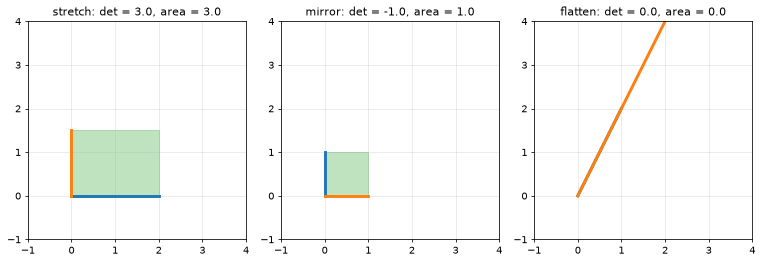

In [10]:
def area(points):
    """Area of a polygon from its corner points (shoelace formula)."""
    x, y = points
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


square = np.array([[0, 1, 1, 0],
                   [0, 0, 1, 1]], dtype=float)
machines = {
    "stretch": np.array([[2.0, 0.0], [0.0, 1.5]]),
    "mirror":  np.array([[0.0, 1.0], [1.0, 0.0]]),
    "flatten": np.array([[1.0, 2.0], [2.0, 4.0]]),
}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (name, M_) in zip(axes, machines.items()):
    image = M_ @ square
    ax.fill(*np.column_stack([image, image[:, 0]]), alpha=0.3, color="C2")
    ax.plot(*image[:, [0, 1]], color="C0", lw=3)    # image of the bottom edge
    ax.plot(*image[:, [3, 0]], color="C1", lw=3)    # image of the left edge
    ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_xlim(-1, 4); ax.set_ylim(-1, 4)
    ax.set_title(f"{name}: det = {np.linalg.det(M_):.1f}, area = {area(image):.1f}")
plt.tight_layout()
plt.show()

Elimination gives another way to compute a determinant: it is the product of the pivots, times $-1$ for every row exchange. Here a matrix that needs one exchange.

In [11]:
A = np.array([[0, 2, 1],
              [1, 1, 1],
              [2, 1, 3]])
pivots = [1, 2, 1.5]            # found by hand after swapping rows 1 and 2
print("product of pivots, times -1 for the swap:", -np.prod(pivots))
print("numpy.linalg.det                        :", round(np.linalg.det(A), 6))

B = np.array([[1, 2], [3, 4]])
C2 = np.array([[0, 1], [1, 2]])
print("det(BC) =", round(np.linalg.det(B @ C2), 6), " det(B) det(C) =", round(np.linalg.det(B) * np.linalg.det(C2), 6))

product of pivots, times -1 for the swap: -3.0
numpy.linalg.det                        : -3.0
det(BC) = 2.0  det(B) det(C) = 2.0


## 4. LU decomposition

Elimination, recorded: $A = LU$. We write the factorization from scratch, storing each multiplier in $L$ at the moment we use it. With `pivoting="partial"` the function also swaps rows (as real libraries do) and returns a permutation matrix $P$ so that $A = PLU$.

In [12]:
def lu_scratch(A, pivoting="none"):
    """Return P, L, U with A = P @ L @ U.

    The multiplier used to clear entry (i, k) is stored in L[i, k].
    pivoting="partial" swaps in the largest available entry first.
    """
    U = np.array(A, dtype=float)
    n = len(U)
    L = np.eye(n)
    perm = np.arange(n)
    for k in range(n):
        if pivoting == "partial":
            p = k + np.argmax(np.abs(U[k:, k]))
            if p != k:
                U[[k, p]] = U[[p, k]]
                perm[[k, p]] = perm[[p, k]]
                L[[k, p], :k] = L[[p, k], :k]
        if U[k, k] == 0:
            raise ValueError(f"no pivot in column {k}")
        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]          # the multiplier goes straight into L
            U[i, k:] -= L[i, k] * U[k, k:]
    P = np.eye(n)[perm].T
    return P, L, U


A = np.array([[2, 1, -1],
              [4, 3,  1],
              [-2, 2, 5]])
P, L, U = lu_scratch(A)
print("L =\n", L)
print("U =\n", U)
print("L @ U equals A:", np.allclose(L @ U, A))

L =
 [[ 1.  0.  0.]
 [ 2.  1.  0.]
 [-1.  3.  1.]]
U =
 [[ 2.  1. -1.]
 [ 0.  1.  3.]
 [ 0.  0. -5.]]
L @ U equals A: True


The numbers 2, -1, and 3 in $L$ are exactly the multipliers from the previous topic. To see **why** they drop in without any extra work, compare with the inverses of the elementary matrices, multiplied in the order of the steps.

In [13]:
E21 = np.array([[1, 0, 0], [-2, 1, 0], [0, 0, 1]])
E31 = np.array([[1, 0, 0], [0, 1, 0], [1, 0, 1]])
E32 = np.array([[1, 0, 0], [0, 1, 0], [0, -3, 1]])

inv = np.linalg.inv
print("E32 @ E31 @ E21 (the combined steps) mixes the multipliers:\n", E32 @ E31 @ E21)
print("inv(E21) @ inv(E31) @ inv(E32) is exactly L:\n", inv(E21) @ inv(E31) @ inv(E32))

E32 @ E31 @ E21 (the combined steps) mixes the multipliers:
 [[ 1  0  0]
 [-2  1  0]
 [ 7 -3  1]]
inv(E21) @ inv(E31) @ inv(E32) is exactly L:
 [[ 1.  0.  0.]
 [ 2.  1.  0.]
 [-1.  3.  1.]]


With row exchanges, compare our partial-pivoting version with SciPy. SciPy returns `P, L, U` with `A = P @ L @ U`, the same convention as here.

In [14]:
rng = np.random.default_rng(4)
A = rng.normal(size=(5, 5))

P1, L1, U1 = lu_scratch(A, pivoting="partial")
P2, L2, U2 = sla.lu(A)

print("A = P L U (mine) :", np.allclose(P1 @ L1 @ U1, A))
print("same P, L, U as SciPy:", np.allclose(P1, P2), np.allclose(L1, L2), np.allclose(U1, U2))

A = P L U (mine) : True
same P, L, U as SciPy: True True True


### Two triangular solves

With $A = LU$, solving $A\mathbf{x} = \mathbf{b}$ means solving $L\mathbf{c} = \mathbf{b}$ (forward substitution, top to bottom) and then $U\mathbf{x} = \mathbf{c}$ (back substitution, bottom to top).

In [15]:
def forward_substitute(L, b):
    n = len(b)
    c = np.zeros(n)
    for i in range(n):
        c[i] = b[i] - L[i, :i] @ c[:i]          # L has ones on its diagonal
    return c


def back_substitute(U, c):
    n = len(c)
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (c[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x


A = np.array([[2, 1, -1], [4, 3, 1], [-2, 2, 5]])
b = np.array([3, 11, 7])
P, L, U = lu_scratch(A)
c = forward_substitute(L, P.T @ b)
x = back_substitute(U, c)
print("c =", c)
print("x =", x, "| numpy.linalg.solve:", np.linalg.solve(A, b))

c = [ 3.  5. -5.]
x = [1. 2. 1.] | numpy.linalg.solve: [1. 2. 1.]


### Factor once, solve many times

The expensive part, about $n^3/3$ multiplications, is the factorization. After that, each new right-hand side costs only about $n^2$. Here 60 different right-hand sides share one matrix: we call `solve` 60 times (refactoring each time), against one `lu_factor` and 60 cheap `lu_solve` calls.

In [16]:
n, k = 800, 60
rng = np.random.default_rng(5)
A = rng.normal(size=(n, n))
rhs = rng.normal(size=(n, k))


def refactor_every_time():
    return np.column_stack([np.linalg.solve(A, rhs[:, j]) for j in range(k)])


def factor_once():
    lu_piv = sla.lu_factor(A)
    return np.column_stack([sla.lu_solve(lu_piv, rhs[:, j]) for j in range(k)])


print("same answers:", np.allclose(refactor_every_time(), factor_once()))
print(f"factoring once is about {best_time(refactor_every_time, 2) / best_time(factor_once, 2):.0f} times faster here (the exact number varies)")

same answers: True


factoring once is about 18 times faster here (the exact number varies)


## 5. Transposes, symmetric matrices, and permutations

The transpose flips rows and columns. The rules below are the ones to remember.

In [17]:
rng = np.random.default_rng(6)
A = rng.normal(size=(3, 4))
B = rng.normal(size=(4, 2))

print("(AB)^T = B^T A^T       :", np.allclose((A @ B).T, B.T @ A.T))
G = A.T @ A
print("A^T A is symmetric     :", np.allclose(G, G.T), "| shape", G.shape)

M3 = rng.normal(size=(3, 3))
print("(M^T)^-1 = (M^-1)^T    :", np.allclose(np.linalg.inv(M3.T), np.linalg.inv(M3).T))

Perm = np.array([[0, 1, 0],
                 [0, 0, 1],
                 [1, 0, 0]])
print("P^-1 = P^T for a permutation matrix:", np.allclose(np.linalg.inv(Perm), Perm.T))

# A symmetric matrix factors as L D L^T
Sym = np.array([[4.0, 2.0], [2.0, 3.0]])
_, Ls, Us = lu_scratch(Sym)
D = np.diag(np.diag(Us))
print("S = L D L^T            :", np.allclose(Ls @ D @ Ls.T, Sym))

(AB)^T = B^T A^T       : True
A^T A is symmetric     : True | shape (4, 4)
(M^T)^-1 = (M^-1)^T    : True
P^-1 = P^T for a permutation matrix: True
S = L D L^T            : True


## Recap and next steps

* Matrix multiplication is associative and distributive, but not commutative. Associativity lets us choose the cheapest order, and without a non-linear step between them, two layers collapse into one matrix.
* The inverse is found by Gauss-Jordan elimination on $[A \mid I]$, exists only when there is a full set of pivots, and reverses order for a product. We solve systems with `solve` instead.
* The determinant is the area (or volume) scaling factor, the product of pivots up to the sign from row exchanges, and it is zero exactly when the matrix is singular.
* $A = LU$ stores elimination: $L$ holds the multipliers, $U$ is the triangular result, and many right-hand sides share one factorization. Row exchanges give $A = PLU$.
* Transposes reverse the order of a product, $A^\top A$ is symmetric, and the inverse of a permutation matrix is its transpose.

**Try it yourself:** change the shear in section 1 to another matrix and predict whether `R @ S` and `S @ R` will still differ. Then do the [exercises](exercises/problems.md) and the [assignment](assignment.md).

Next topic: [Vector Spaces and Subspaces](../vector-spaces-and-subspaces/README.md).